# Identifying effects through safe adjustment

A set is admissible for back-door adjustment when it excludes treatment descendants and blocks every path that enters the treatment:

$$
S\cap\operatorname{De}_G(X)=\varnothing,
\qquad
X\mathbin{\perp\!\!\!\perp}_{G_{\underline X}}Y\mid S.
$$

Here, $G$ is the declared directed graph, $X$ is treatment, $Y$ is outcome, $S$ is the proposed adjustment set, $\operatorname{De}_G(X)$ is the set of descendants of $X$, $G_{\underline X}$ is the graph obtained by deleting arrows that leave $X$, and the separation sign says that $S$ blocks every remaining path from $X$ to $Y$.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("02_graphical_identification");
using CSV, TOML
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
using RiskLabAI.CausalFactorAnalysis: d_separation
default(left_margin=10Plots.mm,bottom_margin=10Plots.mm)
input_directory = joinpath("..","data","chapter02_random_inputs")
table(values,name,caption) = save_table(values,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
matrix_data(values) = DataFrame(values,:auto)
function assert_artifacts(figures,tables)
    @assert all(name->isfile(joinpath(paths.figures,name*".pdf")),figures)
    @assert all(name->isfile(joinpath(paths.tables,name*".tex")),tables)
end
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy;


## Graph structure and path checks

Row,From,To
,String,String
1,Momentum,HML
2,Momentum,Return
3,HML,Order imbalance
4,HML,Return
5,HML,Spread
6,Return,Spread
7,Order imbalance,Return


Row,Candidate,Guidance,Selected
,String,String,String
1,Momentum,Use as common cause,Yes
2,Order imbalance,Exclude as mediator,No
3,Spread,Exclude as collider,No


Row,Condition,Result
,String,String
1,No treatment descendant is selected,Yes
2,Treatment and outcome are separated after outgoing arrows are removed,Yes
3,Momentum is selected,Yes
4,Mediator is excluded,Yes
5,Collider is excluded,Yes


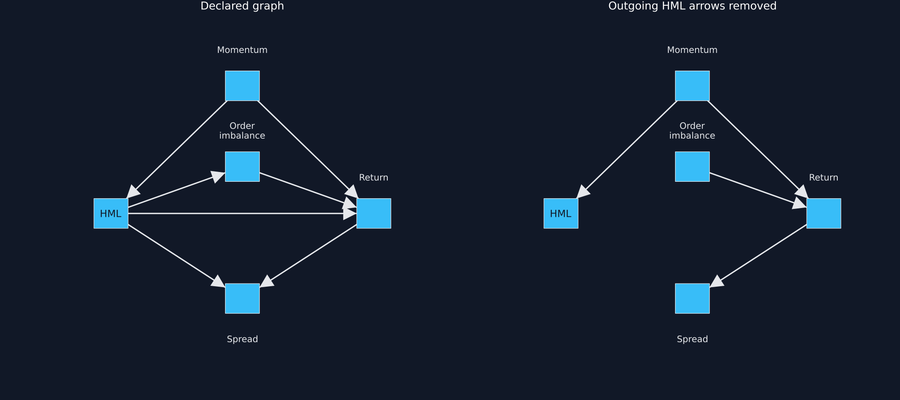

In [1]:
function table(values,name,caption)
    shown = copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column] = ifelse.(shown[!,column],"Yes","No")
        end
    end
    save_table(shown,paths,name;caption,label="tab:chapter24-"*replace(name,"_"=>"-"))
    return nothing
end
store = PrimitiveStore(input_directory,"backdoor")
graph = DirectedGraph([("Momentum","HML"),("Momentum","Return"),("HML","Order imbalance"),("Order imbalance","Return"),("HML","Return"),("HML","Spread"),("Return","Spread")])
treatment,outcome = "HML","Return"
adjustment_set = backdoor_adjustment_set(graph,treatment,outcome)
candidates = ["Momentum","Order imbalance","Spread"]
decisions = flag_controls(graph,treatment,outcome,candidates)
graph_edges = frame(["From","To"],ordered_edges(graph))
decision_text = Dict("valid_confounder"=>"Use as common cause","avoid_mediator"=>"Exclude as mediator","avoid_collider"=>"Exclude as collider")
adjustment_decisions = frame(["Candidate","Guidance","Selected"],[(name,decision_text[decisions[name]],name in adjustment_set) for name in candidates])
backdoor_graph = DirectedGraph(graph.nodes,filter(edge->edge[1]!=treatment,graph.edges))
criterion_checks = DataFrame("Condition"=>["No treatment descendant is selected","Treatment and outcome are separated after outgoing arrows are removed","Momentum is selected","Mediator is excluded","Collider is excluded"],"Result"=>[isempty(intersect(adjustment_set,reachable(graph,treatment))),d_separation(CausalDAG(backdoor_graph.nodes,backdoor_graph.edges,backdoor_graph.nodes),[treatment],[outcome],adjustment_set).separated,adjustment_set==Set(["Momentum"]),!("Order imbalance" in adjustment_set),!("Spread" in adjustment_set)])
table(graph_edges,"backdoor_graph_edges","Declared arrows for the back-door example.")
table(adjustment_decisions,"backdoor_adjustment_decisions","Control decisions returned for three candidate variables.")
table(criterion_checks,"backdoor_criterion_checks","Graphical checks for the selected adjustment set.")
positions = Dict("Momentum"=>(1.,1.5),"HML"=>(0.,0.),"Order imbalance"=>(1.,.55),"Return"=>(2.,0.),"Spread"=>(1.,-1.))
labels = Dict("Order imbalance"=>"Order\nimbalance")
save_figure(plot(identification_graph_panel(graph,positions,"Declared graph";labels),identification_graph_panel(backdoor_graph,positions,"Outgoing HML arrows removed";labels);layout=(1,2),size=(1350,600)),paths,"backdoor_original_mutilated")


## The Adjustment Formula

When the graphical conditions hold, the intervention distribution is obtained by averaging conditional outcome distributions over the adjustment variables:

$$
p(y\mid\operatorname{do}(x))
=\sum_s p(y\mid x,s)p(s).
$$

Here, $x$ is a fixed treatment value, $y$ is an outcome value, $s$ ranges over possible values of the valid adjustment set $S$, $p(y\mid x,s)$ is an observed conditional distribution, $p(s)$ is the marginal distribution of the adjustment variables, and $\operatorname{do}(x)$ denotes an intervention that sets treatment to $x$.

Row,Treatment,Observed outcome chance,Adjusted intervention chance
,Int64,Float64,Float64
1,0,0.107143,0.21
2,1,0.590909,0.46


Row,Comparison,Effect
,String,Float64
1,Observed difference,0.483766
2,Adjusted intervention difference,0.25
3,Known structural difference,0.25


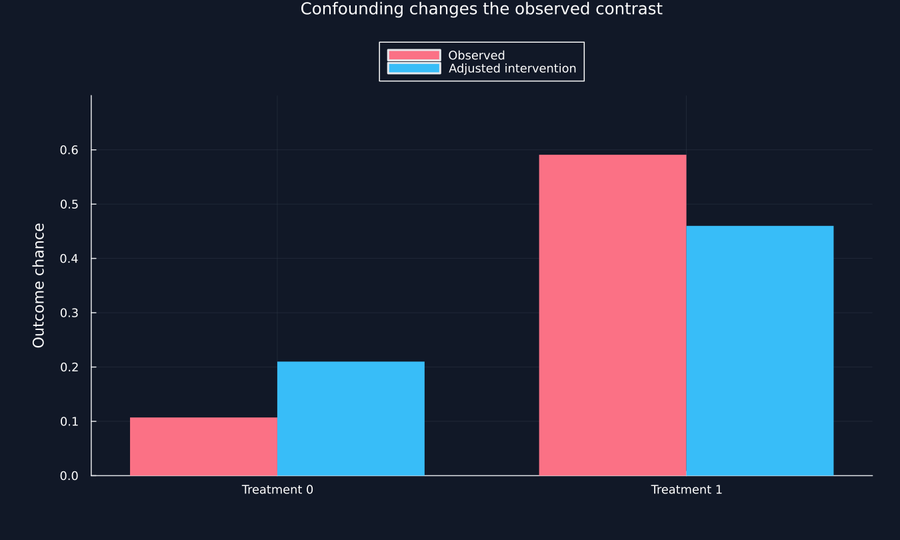

In [2]:
p_c = Dict(0=>.6,1=>.4)
p_x_given_c = Dict((0,0)=>.8,(1,0)=>.2,(0,1)=>.2,(1,1)=>.8)
p_y_given_xc = Dict((x,c)=>.05+.25x+.4c for x in 0:1 for c in 0:1)
observational,adjusted = Dict{Int,Float64}(),Dict{Int,Float64}()
for x in 0:1
    p_x = sum(p_x_given_c[(x,c)]*p_c[c] for c in 0:1)
    observational[x] = sum(p_y_given_xc[(x,c)]*p_x_given_c[(x,c)]*p_c[c] for c in 0:1)/p_x
    adjusted[x] = sum(p_y_given_xc[(x,c)]*p_c[c] for c in 0:1)
end
binary_adjustment = frame(["Treatment","Observed outcome chance","Adjusted intervention chance"],[(x,observational[x],adjusted[x]) for x in 0:1])
binary_effects = DataFrame("Comparison"=>["Observed difference","Adjusted intervention difference","Known structural difference"],"Effect"=>[observational[1]-observational[0],adjusted[1]-adjusted[0],.25])
table(binary_adjustment,"backdoor_binary_adjustment","Observed and adjusted outcome chances in a binary example.")
table(binary_effects,"backdoor_binary_effects","Observed, adjusted, and known effects in the binary example.")
figure = bar((1:2).- .18,[observational[0],observational[1]];bar_width=.36,color=palette.rose,linealpha=0,label="Observed",xticks=(1:2,["Treatment 0","Treatment 1"]),ylabel="Outcome chance",ylims=(0,.7),legend=:outertop,title="Confounding changes the observed contrast",size=(900,540))
bar!(figure,(1:2).+ .18,[adjusted[0],adjusted[1]];bar_width=.36,color=palette.cyan,linealpha=0,label="Adjusted intervention")
save_figure(figure,paths,"backdoor_binary_adjustment_comparison")


## A Known Linear System

The controlled experiment is generated by a common cause, a treatment, a mediator, an outcome, and a downstream common effect:

$$
X=\delta C+\varepsilon_X,\qquad
M=aX+\varepsilon_M,\qquad
Y=dX+bM+\gamma C+\varepsilon_Y,\qquad
K=X+Y+\varepsilon_K.
$$

Here, $C$ is the observed common cause, $X$ is treatment, $M$ is the mediator, $Y$ is outcome, $K$ is the collider, $\delta$ is the common-cause loading on treatment, $a$ is the treatment-to-mediator coefficient, $d$ is the direct effect, $b$ is the mediator-to-outcome coefficient, $\gamma$ is the common-cause loading on outcome, and the four $\varepsilon$ terms are independent standard-normal shocks.

In this linear system, the total effect combines the direct path and the path through the mediator:

$$
\tau_{X\to Y}=d+ab.
$$

Here, $\tau_{X\to Y}$ is the total effect of treatment on outcome, $d$ is the direct-path coefficient, $a$ is the treatment-to-mediator coefficient, and $b$ is the mediator-to-outcome coefficient.

Row,Parameter,Symbol,Value
,String,String,Real
1,Common-cause loading on treatment,delta,0.8
2,Treatment-to-mediator coefficient,a,0.7
3,Direct effect,d,0.5
4,Mediator-to-outcome coefficient,b,0.6
5,Common-cause loading on outcome,gamma,0.9
6,Known total effect,tau,0.92
7,Observations,n,50000


Row,Specification,Treatment coefficient,Target for comparison,Absolute error
,String,Float64,Float64,Float64
1,No adjustment,1.35632,0.92,0.436323
2,Valid common-cause adjustment,0.92016,0.92,0.000159676
3,Common cause and mediator,0.503408,0.5,0.0034078
4,Common cause and collider,-0.188271,0.92,1.10827
5,Common cause and neutral variable,0.920165,0.92,0.000164523


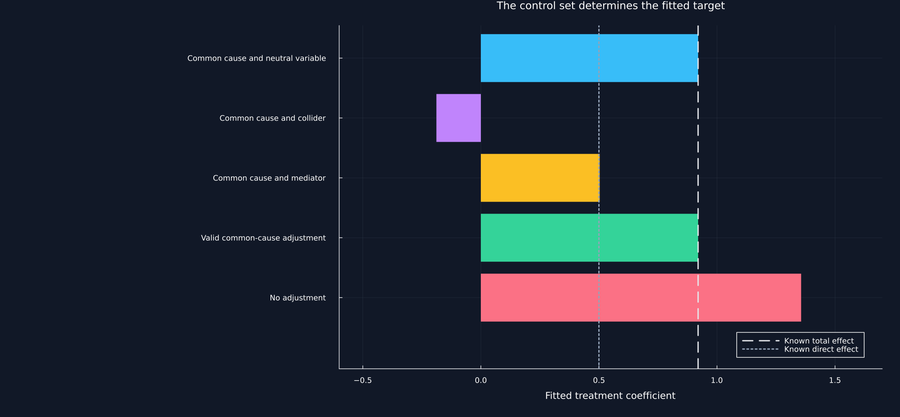

In [3]:
backdoor_parameters = frame(["Parameter","Symbol","Value"],[["Common-cause loading on treatment","delta",0.8],["Treatment-to-mediator coefficient","a",0.7],["Direct effect","d",0.5],["Mediator-to-outcome coefficient","b",0.6],["Common-cause loading on outcome","gamma",0.9],["Known total effect","tau",0.92],["Observations","n",50000]])
total_effect = .5+.7*.6
sample = simulate_backdoor(store,50000)
specifications = ["No adjustment"=>String[],"Valid common-cause adjustment"=>["Common cause"],"Common cause and mediator"=>["Common cause","Mediator"],"Common cause and collider"=>["Common cause","Collider"],"Common cause and neutral variable"=>["Common cause","Neutral"]]
estimate_rows = Tuple[]
for (name,controls) in specifications
    control_values = isempty(controls) ? nothing : Matrix(sample[:,controls])
    estimate = ols_slope(sample.Outcome,sample.Treatment,control_values)
    target = occursin("mediator",lowercase(name)) ? .5 : total_effect
    push!(estimate_rows,(name,estimate,target,abs(estimate-target)))
end
control_estimates = frame(["Specification","Treatment coefficient","Target for comparison","Absolute error"],estimate_rows)
table(backdoor_parameters,"backdoor_structural_parameters","Values used in the known linear back-door experiment.")
table(control_estimates,"backdoor_control_estimates","Treatment coefficients under five control choices.")
save_data(sample,paths,"backdoor_generated_sample")
figure = bar(1:5,control_estimates[!,"Treatment coefficient"];orientation=:horizontal,color=[palette.rose,palette.green,palette.amber,violet,palette.cyan],linealpha=0,label="",yticks=(1:5,control_estimates.Specification),xlims=(-.6,1.7),xlabel="Fitted treatment coefficient",title="The control set determines the fitted target",legend=:bottomright,left_margin=73Plots.mm,size=(1400,650))
vline!(figure,[total_effect];color=palette.text,linestyle=:dash,label="Known total effect")
vline!(figure,[.5];color=muted,linestyle=:dot,label="Known direct effect")
save_figure(figure,paths,"backdoor_control_coefficients")


### Studying recovery across sample and confounding regimes

The bias and root mean squared error across repeated samples are calculated as follows:

$$
\widehat{\operatorname{Bias}}=\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau),
\qquad
\widehat{\operatorname{RMSE}}=\sqrt{\frac{1}{R}\sum_{r=1}^{R}(\widehat\tau_r-\tau)^2}.
$$

Here, $R$ is the number of repeated samples, $r$ labels one sample, $\widehat\tau_r$ is its fitted treatment coefficient, $\tau$ is the known total effect, $\widehat{\operatorname{Bias}}$ is the average signed error, and $\widehat{\operatorname{RMSE}}$ is the square root of the average squared error.

#### Simulation inputs and sample sizes

In [4]:
size_rows = Tuple[]
for n in [250,500,1000,2500,5000,10000,50000]
    data = simulate_backdoor(store,n;seed=240100+n)
    push!(size_rows,(n,ols_slope(data.Outcome,data.Treatment),ols_slope(data.Outcome,data.Treatment,Matrix(data[:,["Common cause"]])),total_effect))
end
sample_size_convergence = frame(["Observations","Unadjusted coefficient","Adjusted coefficient","Known total effect"],size_rows)
table(sample_size_convergence,"backdoor_sample_size_convergence","Treatment coefficients as sample size increases.");


Row,Observations,Unadjusted coefficient,Adjusted coefficient,Known total effect
,Int64,Float64,Float64,Float64
1,250,1.26701,0.856293,0.92
2,500,1.34559,0.878318,0.92
3,1000,1.41376,1.01105,0.92
4,2500,1.38296,0.910876,0.92
5,5000,1.36468,0.933709,0.92
6,10000,1.34851,0.916526,0.92
7,50000,1.36264,0.93094,0.92


#### More observations do not remove omitted-common-cause bias

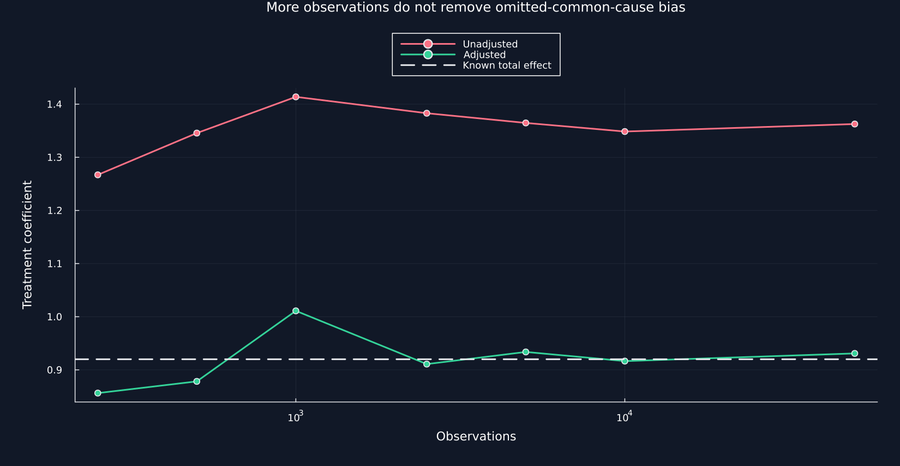

Row,Common-cause loading,Method,Mean coefficient,Bias,Root mean squared error,Repetitions
,Float64,String,Float64,Float64,Float64,Int64
1,0.0,Unadjusted,0.927199,0.00719901,0.0416828,150
2,0.0,Adjusted,0.926669,0.00666935,0.0325602,150
3,0.4,Unadjusted,1.23696,0.316959,0.319096,150
4,0.4,Adjusted,0.923325,0.0033254,0.0305331,150
5,0.8,Unadjusted,1.35884,0.438836,0.439709,150
6,0.8,Adjusted,0.918799,-0.00120119,0.0321418,150
7,1.2,Unadjusted,1.36128,0.44128,0.441886,150
8,1.2,Adjusted,0.922118,0.0021184,0.0328054,150


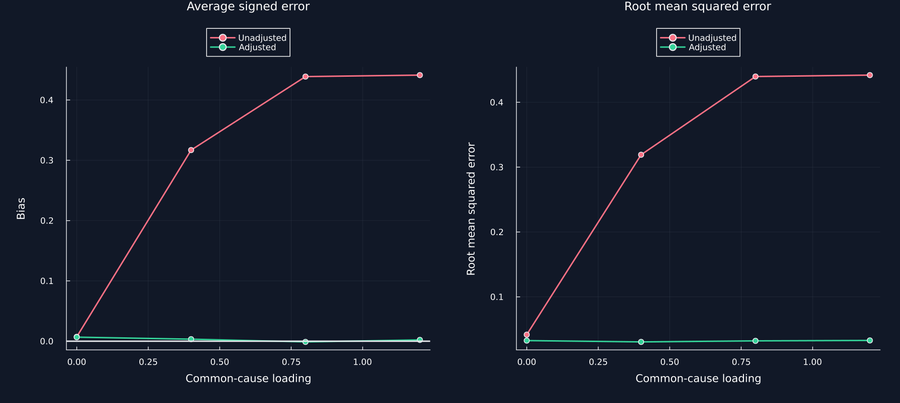

In [4]:
figure = plot(sample_size_convergence.Observations,sample_size_convergence[!,"Unadjusted coefficient"];marker=:circle,color=palette.rose,label="Unadjusted",xscale=:log10,xlabel="Observations",ylabel="Treatment coefficient",title="More observations do not remove omitted-common-cause bias",legend=:outertop,size=(1100,570))
plot!(figure,sample_size_convergence.Observations,sample_size_convergence[!,"Adjusted coefficient"];marker=:circle,color=palette.green,label="Adjusted")
hline!(figure,[total_effect];color=palette.text,linestyle=:dash,label="Known total effect")
save_figure(figure,paths,"backdoor_sample_size_convergence")
sweep_rows,repetition_rows = Tuple[],Tuple[]
repetitions = 150
for delta in [0.,.4,.8,1.2]
    naive_values,adjusted_values = Float64[],Float64[]
    for repetition in 0:repetitions-1
        data = simulate_backdoor(store,1500;delta,seed=240200+repetition+Int(delta*1000))
        naive = ols_slope(data.Outcome,data.Treatment)
        adjusted_value = ols_slope(data.Outcome,data.Treatment,Matrix(data[:,["Common cause"]]))
        push!(naive_values,naive)
        push!(adjusted_values,adjusted_value)
        push!(repetition_rows,(delta,repetition,naive,adjusted_value))
    end
    for (method,values) in [("Unadjusted",naive_values),("Adjusted",adjusted_values)]
        push!(sweep_rows,(delta,method,mean(values),mean(values)-total_effect,sqrt(mean_squared_error(values,total_effect)),repetitions))
    end
end
confounding_sweep = frame(["Common-cause loading","Method","Mean coefficient","Bias","Root mean squared error","Repetitions"],sweep_rows)
table(confounding_sweep,"backdoor_confounding_sweep","Repeated-sample error as common-cause strength increases.")
save_data(frame(["Common-cause loading","Repetition","Unadjusted coefficient","Adjusted coefficient"],repetition_rows),paths,"backdoor_repetitions")
panels = Plots.Plot[]
for (column,title) in [("Bias","Average signed error"),("Root mean squared error","Root mean squared error")]
    panel = plot(;title,xlabel="Common-cause loading",ylabel=column,legend=:outertop)
    for (method,color) in [("Unadjusted",palette.rose),("Adjusted",palette.green)]
        subset = confounding_sweep[confounding_sweep.Method.==method,:]
        plot!(panel,subset[!,"Common-cause loading"],subset[!,column];marker=:circle,color,label=method)
    end
    column=="Bias" && hline!(panel,[0];color=palette.text,label="")
    push!(panels,panel)
end
save_figure(plot(panels...;layout=(1,2),size=(1250,560)),paths,"backdoor_confounding_sweep")


## Checking the method contract at its limits

A fitted adjustment estimate is interpreted relative to the target and graph that were fixed before fitting:

$$
\widehat\tau_S\rightsquigarrow\tau
\quad\text{only if}\quad
S\text{ satisfies the stated identification conditions and the fitted model is suitable}.
$$

Here, $\widehat\tau_S$ is the estimate obtained after adjusting for $S$, $\tau$ is the intended causal quantity, the arrow denotes convergence under repeated sampling, and the qualification records that a selected control set alone does not prove the graph or correct a poor outcome model.

In [5]:
cyclic_graph = DirectedGraph([("A","B"),("B","A")])
undirected_graph = falses(length(graph.nodes),length(graph.nodes))
input_checks = frame(["Check","Expected result","Observed result","Passed"],[contract_result("Cyclic graph",()->backdoor_adjustment_set(cyclic_graph,"A","B"),ArgumentError),contract_result("Missing treatment",()->backdoor_adjustment_set(graph,"Missing","Return"),ArgumentError),contract_result("Undirected graph",()->backdoor_adjustment_set(undirected_graph,"HML","Return"),MethodError)])
backdoor_summary = DataFrame("Question"=>["Which observed set blocks the back-door path?","Does the mediator belong in a total-effect adjustment set?","Does the collider belong in the adjustment set?","Does a larger sample repair omitted-common-cause bias?","Can the graph be proved by the fitted coefficient?"],"Answer"=>[join(sort(collect(adjustment_set)),", "),"No","No","No","No"])
table(input_checks,"backdoor_input_checks","Input checks for the released back-door calculations.")
table(backdoor_summary,"backdoor_section_summary","Main conclusions from the back-door experiments.")


Row,Check,Expected result,Observed result,Passed
,String,String,String,String
1,Cyclic graph,Rejected,Rejected,Yes
2,Missing treatment,Rejected,Rejected,Yes
3,Undirected graph,Rejected,Rejected,Yes


Row,Question,Answer
,String,String
1,Which observed set blocks the back-door path?,Momentum
2,Does the mediator belong in a total-effect adjustment set?,No
3,Does the collider belong in the adjustment set?,No
4,Does a larger sample repair omitted-common-cause bias?,No
5,Can the graph be proved by the fitted coefficient?,No


## Tests

In [6]:
@assert adjustment_set==Set(["Momentum"])
@assert decisions==Dict("Momentum"=>"valid_confounder","Order imbalance"=>"avoid_mediator","Spread"=>"avoid_collider")
@assert all(criterion_checks.Result)
@assert binary_effects[2,"Effect"]≈.25
@assert abs(control_estimates[2,"Treatment coefficient"]-total_effect)<.02
@assert abs(control_estimates[3,"Treatment coefficient"]-.5)<.02
@assert abs(sample_size_convergence[end,"Adjusted coefficient"]-total_effect)<.02
@assert maximum(confounding_sweep[confounding_sweep.Method.=="Adjusted","Root mean squared error"])<maximum(confounding_sweep[confounding_sweep.Method.=="Unadjusted","Root mean squared error"])
@assert all(input_checks.Passed)
assert_artifacts(["backdoor_original_mutilated","backdoor_binary_adjustment_comparison","backdoor_control_coefficients","backdoor_sample_size_convergence","backdoor_confounding_sweep"],["backdoor_graph_edges","backdoor_adjustment_decisions","backdoor_criterion_checks","backdoor_binary_adjustment","backdoor_binary_effects","backdoor_structural_parameters","backdoor_control_estimates","backdoor_sample_size_convergence","backdoor_confounding_sweep","backdoor_input_checks","backdoor_section_summary"])
nothing
